gt len = 3647705
正样本: 1321121
负样本: 2326584
AUC = 0.9789
NDWI AUC = 0.9984


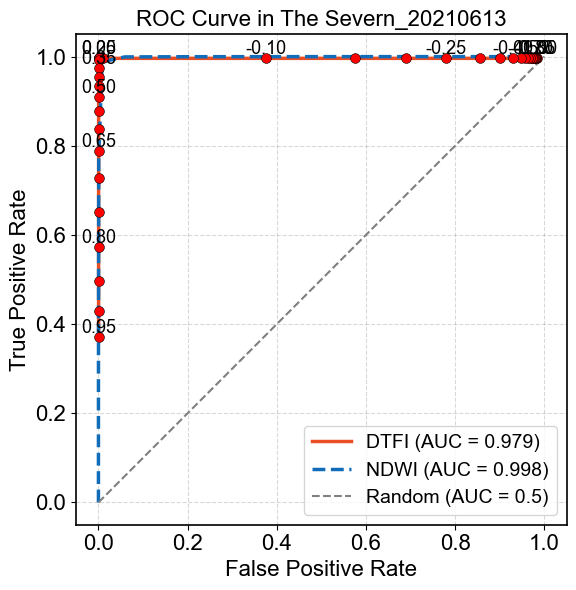

In [71]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import auc

# =========================
# 1. 路径
# =========================
region_list = ['Morecambe_20230904', 'Severn_20210613', 'Solway20220519', 'Thames_20220421', 'Wash20220811'] #Morecambe_20250402_L8.tif
region_list = ['Morecambe_20250402_L8', 'Severn_20210721_L8', 'Solway_20240906_L8', 'Thames_20220421_L8', 'wash_20231125_L8']
name = 'The Severn_20210613'
# region = 'Severn_20210613'

dtfi_tif = f"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408.tif"
gt_tif   = f"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408_id_.tif"


# dtfi_tif = f"H:\ICESat-2\DTFI_display\OTHER\S2_HHK_20240907.tif"
# gt_tif   = f"H:\ICESat-2\DTFI_display\OTHER\S2_HHK_20240907_id.tif"

# region = 'Severn_S2_20220812'
# dtfi_tif = f"H:\ICESat-2\DTFI_display\{region}.tif"
# gt_tif   = f"H:\ICESat-2\DTFI_display\{region}_id.tif"
# # # =========================
# 2. 读取 DTFI
# =========================
with rasterio.open(dtfi_tif) as src:
    dtfi = src.read(6).astype(float)   # Band 5
    dtfi_nodata = src.nodata
    transform1 = src.transform

with rasterio.open(dtfi_tif) as src:
    ndwi = src.read(7).astype(float)   # Band 5
    ndwi_nodata = src.nodata
    transform1 = src.transform

with rasterio.open(gt_tif) as src:
    gt = src.read(1).astype(int)
    gt_nodata = src.nodata
    transform2 = src.transform

if dtfi.shape != gt.shape:
    raise ValueError("DTFI 与 GT 尺寸不一致，请确保使用同一参考栅格生成")
if ndwi.shape != gt.shape:
    raise ValueError("ndwi 与 GT 尺寸不一致，请确保使用同一参考栅格生成")

ndwi = ndwi.flatten()
dtfi = dtfi.flatten()
gt = gt.flatten()

valid_dtfi = ~np.isnan(dtfi)
valid_ndwi = ~np.isnan(ndwi)

if dtfi_nodata is not None:
    valid_dtfi = valid_dtfi & (dtfi != dtfi_nodata)

# GT 只保留 0 / 1
valid_gt = (gt == 0) | (gt == 1)

mask = valid_dtfi & valid_gt & valid_ndwi

dtfi = dtfi[mask]
ndwi = ndwi[mask]
gt = gt[mask]

print('gt len =', len(gt))

n_pos = np.sum(gt == 1)
n_neg = np.sum(gt == 0)

print(f"正样本: {n_pos}")
print(f"负样本: {n_neg}")

if n_pos == 0 or n_neg == 0:
    raise ValueError("GT 中缺少正或负样本")

tpr_list = []
fpr_list = []
acc_list = []
tpr_ndwi_list = []
fpr_ndwi_list = []
acc_ndwi_list = []

thresholds = [-1, -0.9, -0.8, -0.7, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1, 0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]

thresholds = np.arange(-1, 1, 0.05)

for th in thresholds:

    pred = (dtfi >= th).astype(int)
    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    TN = np.sum((pred == 0) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0
    ACC = (TP + TN)/(TP + FP + TN + FN)

    tpr_list.append(TPR)
    fpr_list.append(FPR)
    acc_list.append(ACC)

# thresholds = np.arange(-1, 1, 0.1)

for th in thresholds:

    pred = (ndwi < th).astype(int)
    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    TN = np.sum((pred == 0) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0
    ACC = (TP + TN)/(TP + FP + TN + FN)
    
    acc_ndwi_list.append(ACC)
    tpr_ndwi_list.append(TPR)
    fpr_ndwi_list.append(FPR)

roc_auc = auc(fpr_list, tpr_list)
roc_auc_ndwi = auc(fpr_ndwi_list, tpr_ndwi_list)

print(f"AUC = {roc_auc:.4f}")
print(f"NDWI AUC = {roc_auc_ndwi:.4f}")

# 全局字体设置
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(fpr_list, tpr_list, lw=2.5, color = "#EB4E23FF", label=f'DTFI (AUC = {roc_auc:.3f})')
ax.plot(fpr_ndwi_list, tpr_ndwi_list, lw=2.5, linestyle='--',color = "#116DB9FF", label=f'NDWI (AUC = {roc_auc_ndwi:.3f})')

# ROC 点
ax.scatter(
    fpr_list,
    tpr_list,
    color='red',
    s=50,
    edgecolor='black',
    linewidth=0.4,
    zorder=3
)

# ax.scatter(
#     fpr_ndwi_list,
#     tpr_ndwi_list,
#     color='yellow',
#     s=50,
#     edgecolor='black',
#     linewidth=0.4,
#     zorder=3
# )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    linewidth=1.5,
    label='Random (AUC = 0.5)'
)

step = 3

# thresholds = np.arange(-1, 1, 0.1)
for i in range(0, len(thresholds), step):

    ax.text(
        fpr_list[i],
        tpr_list[i],
        f"{thresholds[i]:.2f}",
        fontsize=13,
        ha='center',
        va='bottom'
    )

for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1.2)

ax.set_title(
    f"ROC Curve in {name}",
    fontsize=16
)

ax.tick_params(
    axis='both',
    labelsize=16
)
ax.set_xlabel(
    "False Positive Rate",
    fontsize=16
)

ax.set_ylabel( "True Positive Rate", fontsize=16)

ax.grid(
    alpha=0.3,
    linestyle='--',
    color='gray'
)
ax.set_aspect('equal')

ax.legend(
    loc='lower right',
    fontsize=14
)

ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)

plt.tight_layout()

plt.show()

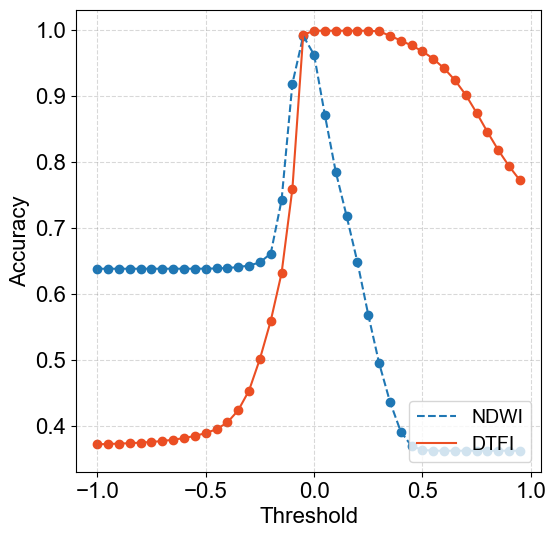

In [72]:
plt.rcParams['font.family'] = 'Arial'
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(thresholds, acc_ndwi_list, linestyle='--',label=f'NDWI')
ax.scatter(thresholds, acc_ndwi_list)

ax.tick_params(
    axis='both',
    labelsize=16
)
ax.set_xlabel(
    "Threshold",
    fontsize=16
)
ax.set_ylabel( "Accuracy", fontsize=16)

ax.grid(
    alpha=0.3,
    linestyle='--',
    color='gray'
)


ax.plot(thresholds, acc_list, color = "#EB4E23FF",label=f'DTFI')
ax.scatter(thresholds, acc_list, color = "#EB4E23FF")

ax.legend(
    loc='lower right',
    fontsize=14
)

In [11]:
import rasterio
import geopandas as gpd
import numpy as np
from rasterio.features import rasterize

# region = 'Wash_20230915_L8'
# === 1. 路径 ===
# input_tif = f"H:\ICESat-2\DTFI_display\OTHER\S2_HHK_20240907.tif"
# output_shp = f"H:\ICESat-2\DTFI_display\OTHER\S2_HHK_20240907.shp"

shp_path =  f"H:\ICESat-2\DTFI_display\OTHER\S2_HHK_20240907.shp"
ref_tif  = f"H:\ICESat-2\DTFI_display\OTHER\S2_HHK_20240907.tif"
out_tif  = f"H:\ICESat-2\DTFI_display\OTHER\S2_HHK_id.tif"

# === 2. 读取 shp ===
gdf = gpd.read_file(shp_path)

# 检查字段
print("字段列表:", gdf.columns)

# === 3. 打开参考影像 ===
with rasterio.open(ref_tif) as src:
    transform = src.transform
    out_shape = (src.height, src.width)
    crs = src.crs

# === 4. CRS 对齐 ===
if gdf.crs != crs:
    gdf = gdf.to_crs(crs)

# === 5. 构建 (geometry, id) ===
# ⚠️ 关键：用 id 字段赋值
shapes = [(geom, int(value)) for geom, value in zip(gdf.geometry, gdf['value'])]

# === 6. 栅格化 ===
raster = rasterize(
    shapes,
    out_shape=out_shape,
    transform=transform,
    fill=0,           # 背景为0
    dtype='int32'     # 用 int，避免 id 截断
)

# === 7. 写出 tif ===
with rasterio.open(
    out_tif,
    'w',
    driver='GTiff',
    height=out_shape[0],
    width=out_shape[1],
    count=1,
    dtype='int32',
    crs=crs,
    transform=transform,
) as dst:
    dst.write(raster, 1)

print("按 id 栅格化完成:", out_tif)

字段列表: Index(['value', 'geometry'], dtype='object')
按 id 栅格化完成: H:\ICESat-2\DTFI_display\OTHER\S2_HHK_id.tif


In [15]:
import geopandas as gpd
import rasterio
from rasterio.mask import mask

# 文件路径
tif_path = r"H:\ICESat-2\DTFI_display\Severn_20210721_L8.tif"
shp_path = r"H:\ICESat-2\DTFI_display\severn_FK.shp"
out_path = r"H:\ICESat-2\DTFI_display\Severn_20210721C_L8.tif"

# 读取矢量
gdf = gpd.read_file(shp_path)

# 确保矢量与栅格坐标系一致（若不同会自动重投影）
with rasterio.open(tif_path) as src:
    # 将矢量转换到栅格的 CRS
    gdf_proj = gdf.to_crs(src.crs)
    # 提取几何图形列表
    shapes = gdf_proj.geometry.values
    # 裁剪
    out_image, out_transform = mask(src, shapes, crop=True, nodata=src.nodata)
    # 更新元数据
    out_meta = src.meta.copy()
    out_meta.update({
        "driver": "GTiff",
        "height": out_image.shape[1],
        "width": out_image.shape[2],
        "transform": out_transform
    })

# 写出裁剪后的栅格
with rasterio.open(out_path, "w", **out_meta) as dest:
    dest.write(out_image)

print("裁剪完成，输出文件：", out_path)

裁剪完成，输出文件： H:\ICESat-2\DTFI_display\Severn_20210721C_L8.tif


样本总数 = 3647705
正样本: 1321121, 负样本: 2326584
AUC (DTFI) = 0.9958
AUC (NDWI) = 0.9991


C:\Users\minyu\AppData\Local\Temp\ipykernel_20016\2663469627.py:89: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 1)


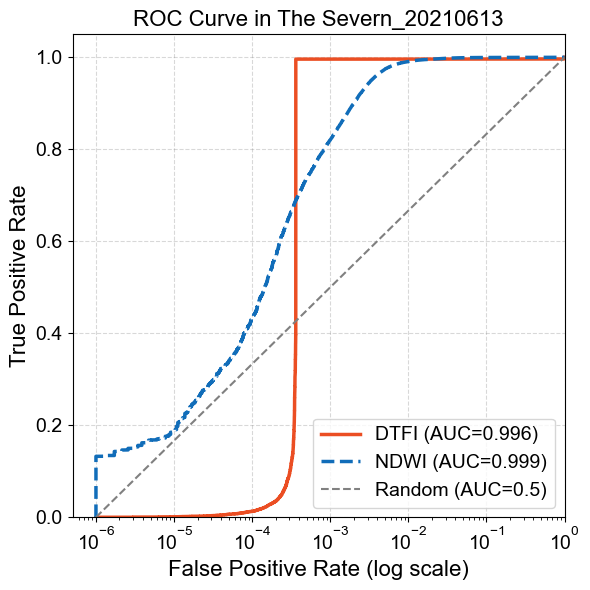

In [53]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# =========================
# 1. 路径
# =========================
region = 'Severn_S2_20220812'
dtfi_tif = f"H:\\ICESat-2\\DTFI_display\\{region}.tif"
gt_tif   = f"H:\\ICESat-2\\DTFI_display\\{region}_id.tif"
name = 'The Severn_20210613'

dtfi_tif = f"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408.tif"
gt_tif   = f"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408_id_.tif"


dtfi_tif = f"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408.tif"
gt_tif   = f"H:\ICESat-2\DTFI_display\OTHER\S2_YC_20220408_id_.tif"
# =========================
# 2. 读取栅格
# =========================
with rasterio.open(dtfi_tif) as src:
    dtfi = src.read(6).astype(float)
    dtfi_nodata = src.nodata

with rasterio.open(dtfi_tif) as src:
    ndwi = src.read(7).astype(float)
    ndwi_nodata = src.nodata

with rasterio.open(gt_tif) as src:
    gt = src.read(1).astype(int)
    gt_nodata = src.nodata

# =========================
# 3. 检查尺寸一致性 & 扁平化
# =========================
if dtfi.shape != gt.shape or ndwi.shape != gt.shape:
    raise ValueError("DTFI/NDWI 与 GT 尺寸不一致")

dtfi = dtfi.flatten()
ndwi = ndwi.flatten()
gt = gt.flatten()

valid_dtfi = ~np.isnan(dtfi) & (dtfi != dtfi_nodata if dtfi_nodata is not None else True)
valid_ndwi = ~np.isnan(ndwi) & (ndwi != ndwi_nodata if ndwi_nodata is not None else True)
valid_gt = (gt == 0) | (gt == 1)

mask = valid_dtfi & valid_ndwi & valid_gt
dtfi = dtfi[mask]
ndwi = ndwi[mask]
gt = gt[mask]

print('样本总数 =', len(gt))
print(f"正样本: {np.sum(gt==1)}, 负样本: {np.sum(gt==0)}")

# =========================
# 4. 使用 sklearn 计算 ROC & AUC
# =========================
# DTFI
fpr_dtfi, tpr_dtfi, thresholds_dtfi = roc_curve(gt, dtfi)
roc_auc_dtfi = auc(fpr_dtfi, tpr_dtfi)

# NDWI（注意 NDWI < 阈值判正样本）
fpr_ndwi, tpr_ndwi, thresholds_ndwi = roc_curve(gt, -ndwi)
roc_auc_ndwi = auc(fpr_ndwi, tpr_ndwi)

print(f"AUC (DTFI) = {roc_auc_dtfi:.4f}")
print(f"AUC (NDWI) = {roc_auc_ndwi:.4f}")

# =========================
# 5. 对数 X 轴绘图
# =========================
plt.rcParams['font.family'] = 'Arial'
fig, ax = plt.subplots(figsize=(6,6))

# 防止 FPR = 0 在 log scale 报错
fpr_dtfi_plot = np.maximum(fpr_dtfi, 1e-6)
fpr_ndwi_plot = np.maximum(fpr_ndwi, 1e-6)

ax.plot(fpr_dtfi_plot, tpr_dtfi, lw=2.5, color="#EB4E23FF", label=f'DTFI (AUC={roc_auc_dtfi:.3f})')
ax.plot(fpr_ndwi_plot, tpr_ndwi, lw=2.5, linestyle='--', color="#116DB9FF", label=f'NDWI (AUC={roc_auc_ndwi:.3f})')

# 对角线
ax.plot([1e-6, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5, label='Random (AUC=0.5)')

# 对数 X 轴设置
ax.set_xscale('log')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.set_xlabel("False Positive Rate (log scale)", fontsize=16)
ax.set_ylabel("True Positive Rate", fontsize=16)
ax.set_title(f"ROC Curve in {name}", fontsize=16)
ax.grid(alpha=0.3, linestyle='--', color='gray')
ax.legend(loc='lower right', fontsize=14)
ax.tick_params(axis='both', labelsize=14)
ax.set_aspect('auto')

# =========================
# 6. 标记几个代表性阈值
# =========================
# 选择 5 个阈值：最小、0.25、0.5、0.75、最大
# indices = [0, len(thresholds_dtfi)//4, len(thresholds_dtfi)//2, 3*len(thresholds_dtfi)//4, -1]
# for i in indices:
#     # ax.scatter(fpr_dtfi_plot[i], tpr_dtfi[i], color='red', s=40, edgecolor='black')
#     # ax.text(fpr_dtfi_plot[i], tpr_dtfi[i], f"{thresholds_dtfi[i]:.2f}", fontsize=12, ha='center', va='bottom')

# indices_ndwi = [0, len(thresholds_ndwi)//4, len(thresholds_ndwi)//2, 3*len(thresholds_ndwi)//4, -1]
# for i in indices_ndwi:
    # ax.scatter(fpr_ndwi_plot[i], tpr_ndwi[i], color='blue', s=40, edgecolor='black')
    # ax.text(fpr_ndwi_plot[i], tpr_ndwi[i], f"{-thresholds_ndwi[i]:.2f}", fontsize=12, ha='center', va='bottom')

plt.tight_layout()
plt.show()